<a href="https://colab.research.google.com/github/titarzra/Tugas-MachineLearning_TitaRizekyRahmadina_202343500097/blob/main/Bab_13_CNN_dan_Transfer_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Bagian A — Implementasi Python

### Praktikum 13.1 Persiapan Library

In [ ]:
import time, pathlib
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
import matplotlib.pyplot as plt

keras.utils.set_random_seed(42)
print("TensorFlow:", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0 | GPU: []


### Praktikum 13.2 Import Dataset

In [ ]:

import os
import shutil

# Lokasi yang menyebabkan error
archive_path = "/root/.keras/datasets/flower_photos.tgz"

# Hapus folder jika nama tersebut ternyata direktori
if os.path.isdir(archive_path):
    shutil.rmtree(archive_path)
    print("Folder yang bentrok berhasil dihapus.")
else:
    print("Tidak ditemukan folder yang bentrok.")


Folder yang bentrok berhasil dihapus.


In [ ]:

import tensorflow as tf
import pathlib
import os
import shutil

# URL dataset
dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"

# Membuat lokasi penyimpanan baru
cache_dir = "/tmp/flower_photos_data"

# Membersihkan folder jika sebelumnya sudah ada
if os.path.exists(cache_dir):
    shutil.rmtree(cache_dir)

# Download dan ekstraksi dataset
archive = tf.keras.utils.get_file(
    fname="flower_photos.tgz",
    origin=dataset_url,
    cache_dir="/tmp",
    cache_subdir="flower_photos_data",
    extract=True
)

# Menentukan lokasi dataset
data_dir = pathlib.Path(cache_dir) / "flower_photos"

# Pemeriksaan
print("Lokasi archive:", archive)
print("Lokasi dataset:", data_dir)
print("Dataset ditemukan:", data_dir.exists())

# Melihat isi folder
print("Isi folder:", os.listdir(cache_dir))

# Memastikan dataset tersedia
if data_dir.exists():
    print("BERHASIL! Dataset berhasil ditemukan.")
else:
    print("GAGAL! Folder dataset belum ditemukan.")


228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Lokasi archive: /tmp/flower_photos_data/flower_photos_extracted
Lokasi dataset: /tmp/flower_photos_data/flower_photos
Dataset ditemukan: False
Isi folder: ['flower_photos_extracted', 'flower_photos.tgz']
GAGAL! Folder dataset belum ditemukan.


In [ ]:

import pathlib
import os

# Mengambil lokasi hasil ekstraksi
data_dir = pathlib.Path(archive)

# Memeriksa isi folder hasil ekstraksi
print("Isi folder ekstraksi:")
print(os.listdir(data_dir))

# Memeriksa folder flower_photos
if (data_dir / "flower_photos").exists():
    data_dir = data_dir / "flower_photos"

print("\nLokasi dataset:", data_dir)
print("Dataset ditemukan:", data_dir.exists())
print("Isi dataset:", os.listdir(data_dir))


Isi folder ekstraksi:
['flower_photos']

Lokasi dataset: /tmp/flower_photos_data/flower_photos_extracted/flower_photos
Dataset ditemukan: True
Isi dataset: ['LICENSE.txt', 'sunflowers', 'tulips', 'dandelion', 'roses', 'daisy']


In [ ]:

IMG_SIZE = (160, 160)
BATCH_SIZE = 32
EPOCHS_TL = 15

# Dataset training
train_raw = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# Dataset validation
val_raw = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# Menampilkan kelas
class_names = train_raw.class_names
jumlah_kelas = len(class_names)

print("Kelas:", class_names)
print("Jumlah kelas:", jumlah_kelas)


Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.
Kelas: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Jumlah kelas: 5


### Praktikum 13.3 Preprocessing

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_raw.map(lambda x, y: (preprocess_input(x), y)).cache().prefetch(AUTOTUNE)
val_ds = val_raw.map(lambda x, y: (preprocess_input(x), y)).cache().prefetch(AUTOTUNE)

### Praktikum 13.4 Training Model (Transfer Learning dengan MobileNetV2)

In [ ]:
base_model = MobileNetV2(input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
base_model.trainable = False      # Feature extraction: bekukan bobot pre-trained

model_tl = keras.Sequential([
    base_model,
    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(jumlah_kelas, activation="softmax"),
])
model_tl.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

t0 = time.perf_counter()
history = model_tl.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_TL)
waktu_tl = time.perf_counter() - t0
print(f"Waktu pelatihan Transfer Learning: {waktu_tl:.0f} detik")

Epoch 1/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 94s 958ms/step - accuracy: 0.7711 - loss: 0.6045 - val_accuracy: 0.8787 - val_loss: 0.3601
Epoch 2/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 126s 798ms/step - accuracy: 0.9022 - loss: 0.2895 - val_accuracy: 0.8992 - val_loss: 0.3449
Epoch 3/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 75s 817ms/step - accuracy: 0.9349 - loss: 0.2014 - val_accuracy: 0.8896 - val_loss: 0.3580
Epoch 4/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 82s 820ms/step - accuracy: 0.9516 - loss: 0.1423 - val_accuracy: 0.8965 - val_loss: 0.3191
Epoch 5/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 74s 805ms/step - accuracy: 0.9717 - loss: 0.0938 - val_accuracy: 0.8856 - val_loss: 0.3529
Epoch 6/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 93s 927ms/step - accuracy: 0.9751 - loss: 0.0796 - val_accuracy: 0.8910 - val_loss: 0.3487
Epoch 7/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 131s 803ms/step - accuracy: 0.9847 - loss: 0.0601 - val_accuracy: 0.8896 - val_loss: 0.3506
Epoch 8/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 76s 823ms/step - accuracy: 0.9891 - loss: 0.0417 - val_ac

### Praktikum 13.5 Evaluasi

In [27]:
val_loss, val_acc_tl = model_tl.evaluate(val_ds)
print(f"Akurasi Validasi: {val_acc_tl:.3f}")

23/23 ━━━━━━━━━━━━━━━━━━━━ 19s 773ms/step - accuracy: 0.9005 - loss: 0.4213
Akurasi Validasi: 0.901


### Praktikum 13.6 Visualisasi

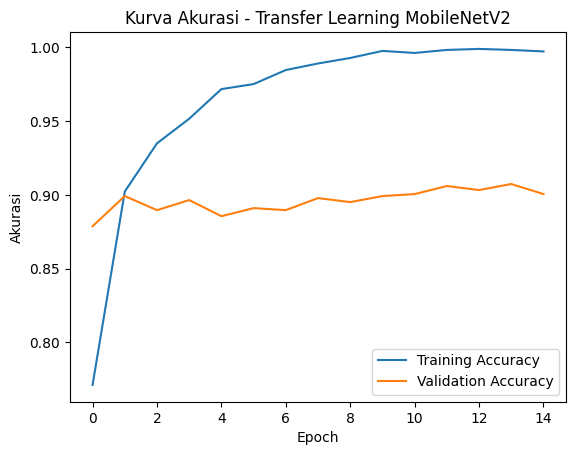

In [28]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch"); plt.ylabel("Akurasi")
plt.title("Kurva Akurasi - Transfer Learning MobileNetV2")
plt.legend(); plt.show()

In [30]:
# (Opsional) Fine-tuning: unfreeze sebagian layer terakhir, latih ulang dengan learning rate sangat kecil
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False
model_tl.compile(optimizer=keras.optimizers.Adam(1e-5), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history_ft = model_tl.fit(train_ds, validation_data=val_ds, epochs=5)
print("Akurasi validasi setelah fine-tuning:", round(history_ft.history["val_accuracy"][-1], 3))

Epoch 1/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 117s 1s/step - accuracy: 0.9905 - loss: 0.0439 - val_accuracy: 0.9074 - val_loss: 0.4108
Epoch 2/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 103s 1s/step - accuracy: 0.9966 - loss: 0.0244 - val_accuracy: 0.9114 - val_loss: 0.4106
Epoch 3/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 106s 1s/step - accuracy: 0.9959 - loss: 0.0202 - val_accuracy: 0.9142 - val_loss: 0.4024
Epoch 4/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 107s 1s/step - accuracy: 0.9993 - loss: 0.0136 - val_accuracy: 0.9142 - val_loss: 0.4012
Epoch 5/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 141s 1s/step - accuracy: 0.9997 - loss: 0.0114 - val_accuracy: 0.9128 - val_loss: 0.4016
Akurasi validasi setelah fine-tuning: 0.913


## Bagian B — Latihan Praktikum

In [ ]:
(x_tr, y_tr), (x_te, y_te) = keras.datasets.cifar10.load_data()
y_tr, y_te = y_tr.ravel(), y_te.ravel()
cifar_kelas = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
print(x_tr.shape, x_te.shape)

EPOCHS_CNN = 10
EPOCHS_CIFAR_TL = 5

# --- (a) CNN dari nol (arsitektur modul, ditambah normalisasi piksel)
keras.utils.set_random_seed(42)
model_cnn = keras.Sequential([
    keras.layers.Input(shape=(32, 32, 3)),
    keras.layers.Rescaling(1 / 255),
    keras.layers.Conv2D(32, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Conv2D(64, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Flatten(),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])
model_cnn.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model_cnn.summary()
t0 = time.perf_counter()
h_cnn = model_cnn.fit(x_tr, y_tr, validation_split=0.1, epochs=EPOCHS_CNN, batch_size=64, verbose=2)
waktu_cnn = time.perf_counter() - t0
acc_cnn = model_cnn.evaluate(x_te, y_te, verbose=0)[1]
print(f"\nCNN dari nol: akurasi test = {acc_cnn:.3f}, waktu = {waktu_cnn:.0f} detik")

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 557s 3us/step
(50000, 32, 32, 3) (10000, 32, 32, 3)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 167,562 (654.54 KB)

 Trainable params: 167,562 (654.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
704/704 - 57s - 81ms/step - accuracy: 0.4561 - loss: 1.5202 - val_accuracy: 0.5378 - val_loss: 1.2942
Epoch 2/10
704/704 - 54s - 77ms/step - accuracy: 0.5828 - loss: 1.1850 - val_accuracy: 0.5988 - val_loss: 1.1315
Epoch 3/10
704/704 - 54s - 77ms/step - accuracy: 0.6325 - loss: 1.0546 - val_accuracy: 0.6374 - val_loss: 1.0416
Epoch 4/10
704/704 - 55s - 78ms/step - accuracy: 0.6622 - loss: 0.9699 - val_accuracy: 0.6542 - val_loss: 0.9974
Epoch 5/10
704/704 - 54s - 77ms/step - accuracy: 0.6864 - loss: 0.9043 - val_accuracy: 0.6664 - val_loss: 0.9622
Epoch 6/10
704/704 - 55s - 78ms/step - accuracy: 0.7062 - loss: 0.8487 - val_accuracy: 0.6732 - val_loss: 0.9531
Epoch 7/10
704/704 - 81s - 115ms/step - accuracy: 0.7218 - loss: 0.8021 - val_accuracy: 0.6808 - val_loss: 0.9481
Epoch 8/10
704/704 - 54s - 77ms/step - accuracy: 0.7367 - loss: 0.7618 - val_accuracy: 0.6906 - val_loss: 0.9264
Epoch 9/10
704/704 - 82s - 117ms/step - accuracy: 0.7485 - loss: 0.7281 - val_accuracy: 0.6928 

In [32]:
# --- (b) Transfer Learning MobileNetV2 pada CIFAR-10 (citra diperbesar 32 -> 96)
keras.utils.set_random_seed(42)
base_c = MobileNetV2(input_shape=(96, 96, 3), include_top=False, weights="imagenet")
base_c.trainable = False
model_cifar_tl = keras.Sequential([
    keras.layers.Input(shape=(32, 32, 3)),
    keras.layers.Resizing(96, 96),
    keras.layers.Rescaling(1 / 127.5, offset=-1),          # sama dengan preprocess_input MobileNetV2
    base_c,
    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(10, activation="softmax"),
])
model_cifar_tl.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
t0 = time.perf_counter()
h_ctl = model_cifar_tl.fit(x_tr, y_tr, validation_split=0.1, epochs=EPOCHS_CIFAR_TL, batch_size=64, verbose=2)
waktu_ctl = time.perf_counter() - t0
acc_ctl = model_cifar_tl.evaluate(x_te, y_te, verbose=0)[1]
print(f"\nTransfer Learning: akurasi test = {acc_ctl:.3f}, waktu = {waktu_ctl:.0f} detik")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
704/704 - 381s - 542ms/step - accuracy: 0.7699 - loss: 0.6885 - val_accuracy: 0.8538 - val_loss: 0.4186
Epoch 2/5
704/704 - 370s - 525ms/step - accuracy: 0.8350 - loss: 0.4843 - val_accuracy: 0.8594 - val_loss: 0.4006
Epoch 3/5
704/704 - 372s - 528ms/step - accuracy: 0.8465 - loss: 0.4528 - val_accuracy: 0.8628 - val_loss: 0.3929
Epoch 4/5
704/704 - 386s - 548ms/step - accuracy: 0.8484 - loss: 0.4466 - val_accuracy: 0.8636 - val_loss: 0.3898
Epoch 5/5
704/704 - 382s - 543ms/step - accuracy: 0.8489 - loss: 0.4395 - val_accuracy: 0.8668 - val_loss: 0.3858

Transfer Learning: akurasi test = 0.857, waktu = 1892 detik


,Epoch,Akurasi test,Waktu latih (s),Parameter total,Parameter dilatih
Model,,,,,
CNN dari nol,10,0.673,629.639,167562,167562
MobileNetV2 (beku) + head,5,0.857,1892.011,2270794,12810


Akurasi test lebih tinggi: MobileNetV2 (beku) + head (selisih 18.4 poin)


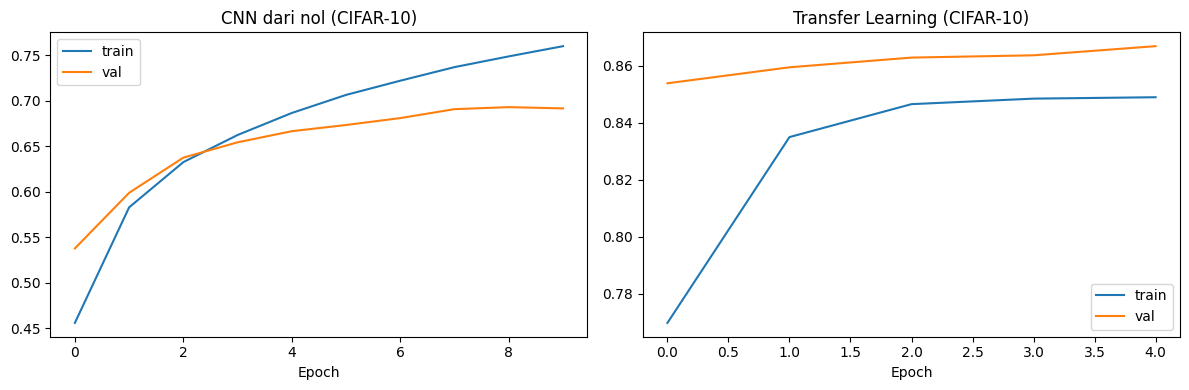

In [33]:
def param_latih(m): return int(sum(np.prod(v.shape) for v in m.trainable_weights))
tabel1 = pd.DataFrame([
    {"Model": "CNN dari nol", "Epoch": EPOCHS_CNN, "Akurasi test": acc_cnn, "Waktu latih (s)": waktu_cnn,
     "Parameter total": model_cnn.count_params(), "Parameter dilatih": param_latih(model_cnn)},
    {"Model": "MobileNetV2 (beku) + head", "Epoch": EPOCHS_CIFAR_TL, "Akurasi test": acc_ctl, "Waktu latih (s)": waktu_ctl,
     "Parameter total": model_cifar_tl.count_params(), "Parameter dilatih": param_latih(model_cifar_tl)},
]).set_index("Model")
display(tabel1.round(3))
lebih = tabel1["Akurasi test"].idxmax()
print(f"Akurasi test lebih tinggi: {lebih} (selisih {abs(acc_cnn - acc_ctl) * 100:.1f} poin)")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h_cnn.history["accuracy"], label="train"); ax[0].plot(h_cnn.history["val_accuracy"], label="val")
ax[0].set_title("CNN dari nol (CIFAR-10)"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(h_ctl.history["accuracy"], label="train"); ax[1].plot(h_ctl.history["val_accuracy"], label="val")
ax[1].set_title("Transfer Learning (CIFAR-10)"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
# CNN dari nol pada flower_photos (data mentah 0-255, normalisasi di dalam model)
keras.utils.set_random_seed(42)
model_scratch = keras.Sequential([
    keras.layers.Input(shape=IMG_SIZE + (3,)),
    keras.layers.Rescaling(1 / 255),
    keras.layers.Conv2D(32, (3, 3), activation="relu"), keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Conv2D(64, (3, 3), activation="relu"), keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Conv2D(128, (3, 3), activation="relu"), keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation="relu"), keras.layers.Dropout(0.3),
    keras.layers.Dense(jumlah_kelas, activation="softmax"),
])
model_scratch.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

train_s = train_raw.cache().prefetch(AUTOTUNE)
val_s = val_raw.cache().prefetch(AUTOTUNE)
t0 = time.perf_counter()
h_scratch = model_scratch.fit(train_s, validation_data=val_s, epochs=EPOCHS_TL)
waktu_scratch = time.perf_counter() - t0
val_acc_scratch = model_scratch.evaluate(val_s, verbose=0)[1]
print(f"CNN dari nol: akurasi validasi = {val_acc_scratch:.3f}, waktu = {waktu_scratch:.0f} detik")

Epoch 1/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 192s 2s/step - accuracy: 0.4380 - loss: 1.3055 - val_accuracy: 0.5586 - val_loss: 1.0729
Epoch 2/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 173s 2s/step - accuracy: 0.6039 - loss: 0.9984 - val_accuracy: 0.6240 - val_loss: 0.9562
Epoch 3/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 174s 2s/step - accuracy: 0.6880 - loss: 0.8405 - val_accuracy: 0.6458 - val_loss: 0.9057
Epoch 4/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 203s 2s/step - accuracy: 0.7374 - loss: 0.6804 - val_accuracy: 0.6226 - val_loss: 1.0561
Epoch 5/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 174s 2s/step - accuracy: 0.7984 - loss: 0.5519 - val_accuracy: 0.6649 - val_loss: 0.8912
Epoch 6/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 204s 2s/step - accuracy: 0.8294 - loss: 0.4870 - val_accuracy: 0.7112 - val_loss: 0.8654
Epoch 7/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 183s 2s/step - accuracy: 0.8706 - loss: 0.3675 - val_accuracy: 0.7016 - val_loss: 0.9875
Epoch 8/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 174s 2s/step - accuracy: 0.9029 - loss: 0.2796 - val_accuracy: 0.6907 - v

In [ ]:
# Model transfer learning dari Bagian A: hitung ulang metrik secara konsisten
# (jika fine-tuning opsional dijalankan, 'model_tl' sudah berubah; jalankan ulang sel Praktikum 13.4 bila ingin membandingkan versi feature extraction murni)
val_acc_tl_final = model_tl.evaluate(val_ds, verbose=0)[1]
tabel2 = pd.DataFrame([
    {"Pendekatan": "CNN dari nol", "Akurasi train (akhir)": h_scratch.history["accuracy"][-1],
     "Akurasi validasi": val_acc_scratch, "Waktu latih (s)": waktu_scratch,
     "Parameter total": model_scratch.count_params(), "Parameter dilatih": param_latih(model_scratch)},
    {"Pendekatan": "Transfer Learning MobileNetV2", "Akurasi train (akhir)": history.history["accuracy"][-1],
     "Akurasi validasi": val_acc_tl_final, "Waktu latih (s)": waktu_tl,
     "Parameter total": model_tl.count_params(), "Parameter dilatih": param_latih(model_tl)},
]).set_index("Pendekatan")
tabel2["Gap train-val"] = tabel2["Akurasi train (akhir)"] - tabel2["Akurasi validasi"]
display(tabel2.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
ax[0].plot(h_scratch.history["accuracy"], label="train"); ax[0].plot(h_scratch.history["val_accuracy"], label="val")
ax[0].set_title("CNN dari nol"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train"); ax[1].plot(history.history["val_accuracy"], label="val")
ax[1].set_title("Transfer Learning MobileNetV2"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

print(f"Akurasi validasi lebih tinggi: {tabel2['Akurasi validasi'].idxmax()} "
      f"(selisih {abs(val_acc_scratch - val_acc_tl_final) * 100:.1f} poin)")
print(f"Parameter yang dilatih: CNN dari nol {param_latih(model_scratch):,} vs Transfer Learning {param_latih(model_tl):,}")